# **Проект по анализу датасета**

## БМБ2410
## Маслюков Михаил Владимирович
## Кротиков Георгий Александрович


**Цель проекта:** подготовить датасет к анализу/моделированию оттока, проверить качество данных, визуализировать распределения, реализовать два метода удаления выбросов и перекодировать категориальные признаки.

> Исходный файл: `netflix_customer_churn.csv`. Целевой признак — `churned`: `1` означает отток клиента, `0` — отсутствие оттока.

Блокнот использует pandas, numpy, matplotlib, scikit-learn и другие библиотеки. Блокнот рассчитан на запуск в одной папке с исследуемым датасетом.


In [1]:
import numpy as np
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder, OrdinalEncoder
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
)

## 1. Загрузка и краткое описание данных

In [2]:

df_raw = pd.read_csv('netflix_customer_churn.csv')
df = df_raw.copy()

df.head()

,customer_id,age,gender,subscription_type,watch_hours,last_login_days,region,device,monthly_fee,churned,payment_method,number_of_profiles,avg_watch_time_per_day,favorite_genre
0,a9b75100-82a8-427a-a208-72f24052884a,51,Other,Basic,14.73,29,Africa,TV,8.99,1,Gift Card,1,0.49,Action
1,49a5dfd9-7e69-4022-a6ad-0a1b9767fb5b,47,Other,Standard,0.70,19,Europe,Mobile,13.99,1,Gift Card,5,0.03,Sci-Fi
2,4d71f6ce-fca9-4ff7-8afa-197ac24de14b,27,Female,Standard,16.32,10,Asia,TV,13.99,0,Crypto,2,1.48,Drama
3,d3c72c38-631b-4f9e-8a0e-de103cad1a7d,53,Other,Premium,4.51,12,Oceania,TV,17.99,1,Crypto,2,0.35,Horror
4,4e265c34-103a-4dbb-9553-76c9aa47e946,56,Other,Standard,1.89,13,Africa,Mobile,13.99,1,Crypto,2,0.13,Action


In [3]:

target = "churned"
IDS = ["customer_id"]



print(f'Кол-во строк: {df.shape[0]}')
print(f'Кол-во столбцов: {df.shape[1]}')

print("Целевой признак: ", end="")
print(target)

column_overview = pd.DataFrame({
    "тип данных": df.dtypes.astype(str),
    "непропущенных": df.notna().sum(),
    "пропусков": df.isna().sum(),
    "уникальных значений": df.nunique(dropna=False),
})
column_overview

Кол-во строк: 5000
Кол-во столбцов: 14
Целевой признак: churned


,тип данных,непропущенных,пропусков,уникальных значений
customer_id,str,5000,0,5000
age,int64,5000,0,53
gender,str,5000,0,3
subscription_type,str,5000,0,3
watch_hours,float64,5000,0,2343
last_login_days,int64,5000,0,61
region,str,5000,0,6
device,str,5000,0,5
monthly_fee,float64,5000,0,3
churned,int64,5000,0,2


### Краткое описание

В наборе **5 000 строк и 14 столбцов**:

- `customer_id` — уникальный строковый идентификатор, он исключается из статистического анализа и кодирования;
- 6 категориальных предикторов: `gender`, `subscription_type`, `region`, `device`, `payment_method`, `favorite_genre`;
- 6 количественных предикторов: `age`, `watch_hours`, `last_login_days`, `monthly_fee`, `number_of_profiles`, `avg_watch_time_per_day`;
- `churned` — бинарный целевой признак (`int64`).

Столбцы `monthly_fee`, `number_of_profiles` и `last_login_days` числовые, но принимают дискретные значения; это следует учитывать при интерпретации графиков.

| Признак | Тип данных | Значения / диапазон в исходном CSV | Описание |
| :--- | :--- | :--- | :--- |
| `customer_id` | строковый | 5 000 уникальных идентификаторов | Технический идентификатор клиента; не используется как предиктор. |
| `age` | целое число | 18–70 | Возраст клиента. |
| `gender` | категориальный | Female, Male, Other | Категория пола в исходном файле. |
| `subscription_type` | категориальный | Basic, Standard, Premium | Тип подписки. |
| `watch_hours` | вещественное число | 0,01–110,40 | Значение часов просмотра; период в самом CSV не уточнён. |
| `last_login_days` | целое число | 0–60 | Число дней с последнего входа. |
| `region` | категориальный | Africa, Asia, Europe, North America, Oceania, South America | Регион клиента. |
| `device` | категориальный | Desktop, Laptop, Mobile, Tablet, TV | Устройство для просмотра. |
| `monthly_fee` | вещественное число | 8,99; 13,99; 17,99 | Размер месячной платы; валюта в CSV не указана. |
| `churned` | целое число | 0 (нет оттока), 1 (отток) | Целевая переменная. |
| `payment_method` | категориальный | Credit Card, Crypto, Debit Card, Gift Card, PayPal | Способ оплаты. |
| `number_of_profiles` | целое число | 1–5 | Число профилей в аккаунте. |
| `avg_watch_time_per_day` | вещественное число | 0,00–98,42 | Среднее дневное время просмотра по названию признака; единицы в CSV явно не описаны. |
| `favorite_genre` | категориальный | Action, Comedy, Documentary, Drama, Horror, Romance, Sci-Fi | Любимый жанр по данным файла. |

Диапазоны указаны для исходного CSV, до обработки пропусков и выбросов; крайние значения могут быть статистическими выбросами.

## 2. Проверка качества данных и обработка пропусков

In [4]:
missing_before = df.isna().sum().rename("Пропуски до обработки")

full_duplicates = df.duplicated().sum()
print("Полных дубликатов строк:", full_duplicates)

df = df.drop_duplicates().copy()

if "customer_id" in df.columns:
    duplicate_ids = df["customer_id"].duplicated().sum()
    print("Повторяющихся customer_id:", duplicate_ids)
    if duplicate_ids > 0:
        df = df.drop_duplicates(subset="customer_id", keep="first").copy()
else:
    print("Столбец customer_id не найден.")

print("Строк после удаления дубликатов:", len(df))
print("Пропуски в оставшихся данных:")
display(df.isna().sum().to_frame("Количество пропусков"))

Полных дубликатов строк: 0
Повторяющихся customer_id: 0
Строк после удаления дубликатов: 5000
Пропуски в оставшихся данных:


,Количество пропусков
customer_id,0
age,0
gender,0
subscription_type,0
watch_hours,0
last_login_days,0
region,0
device,0
monthly_fee,0
churned,0


Дубликаты удаляются до анализа: сначала полные копии строк, затем повторные `customer_id` (для этого датасета одна строка соответствует одному клиенту; при повторе сохраняется первая запись). Числовые пропуски заполняются средним внутри `subscription_type`, категориальные — наиболее частым значением внутри группы, с резервной глобальной модой. Строки без целевой переменной `churned` исключаются.

После заполнения пропусков данные перейдут к удалению выбросов. Итоговый датафрейм `df_clean` будет использоваться во всех дальнейших статистиках, графиках, кодировании, корреляциях и моделировании.

In [ ]:
def fill_numeric_missing_by_group_mean(data, numeric_columns, group_column):
    result = data.copy()

    for feature in numeric_columns:
        group_means = result.groupby(group_column)[feature].transform("mean")
        result[feature] = result[feature].fillna(group_means)
        result[feature] = result[feature].fillna(result[feature].mean())

    return result


def most_common_value(values):
    modes = values.dropna().mode()
    return modes.iloc[0] if not modes.empty else np.nan


def fill_categorical_missing_by_group_mode(data, categorical_columns, group_column):
    result = data.copy()

    for feature in categorical_columns:
        if feature == group_column:
            continue

        group_modes = result.groupby(group_column)[feature].transform(most_common_value)
        result[feature] = result[feature].fillna(group_modes)
        result[feature] = result[feature].fillna(most_common_value(result[feature]))

    return result


numeric_predictors = [
    "age",
    "watch_hours",
    "last_login_days",
    "monthly_fee",
    "number_of_profiles",
    "avg_watch_time_per_day",
]

categorical_predictors = [
    "gender",
    "subscription_type",
    "region",
    "device",
    "payment_method",
    "favorite_genre",
]

df_prepared = df.dropna(subset=[target]).copy()
subscription_mode = df_prepared["subscription_type"].mode()

if not subscription_mode.empty:
    df_prepared["subscription_type"] = df_prepared["subscription_type"].fillna(
        subscription_mode.iloc[0]
    )

df_prepared = fill_numeric_missing_by_group_mean(
    df_prepared,
    numeric_predictors,
    group_column="subscription_type",
)
df_prepared = fill_categorical_missing_by_group_mode(
    df_prepared,
    categorical_predictors,
    group_column="subscription_type",
)

missings_after = df_prepared.isna().sum()
print("Строк после обработки пропусков:", len(df_prepared))
display(pd.DataFrame({
    "Пропуски до": missing_before,
    "Пропуски после заполнения": missings_after,
}))


Строк после обработки пропусков: 5000


,Пропуски до,Пропуски после заполнения
customer_id,0,0
age,0,0
gender,0,0
subscription_type,0,0
watch_hours,0,0
last_login_days,0,0
region,0,0
device,0,0
monthly_fee,0,0
churned,0,0


## 3. Ящики с усами для количественных признаков

Графики показывают медиану, интерквартильный размах (IQR), «усы» и потенциальные выбросы.

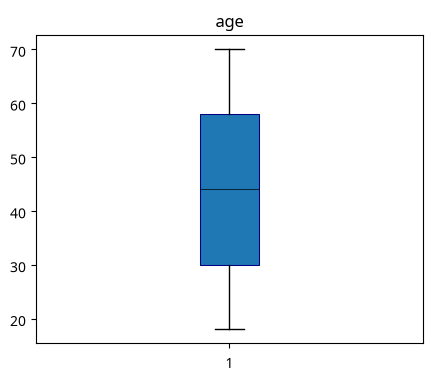

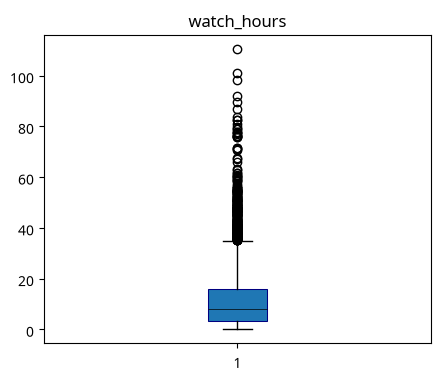

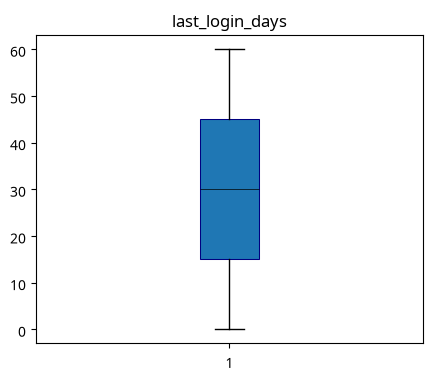

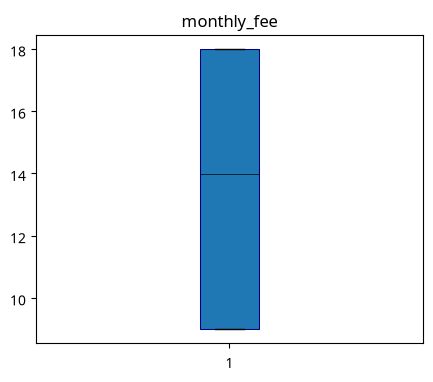

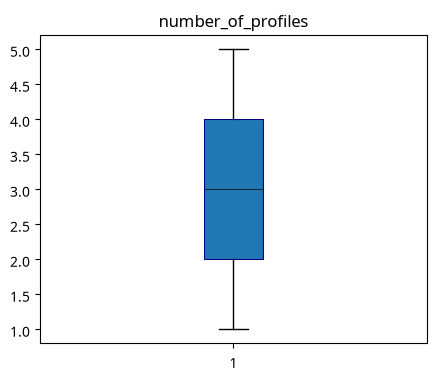

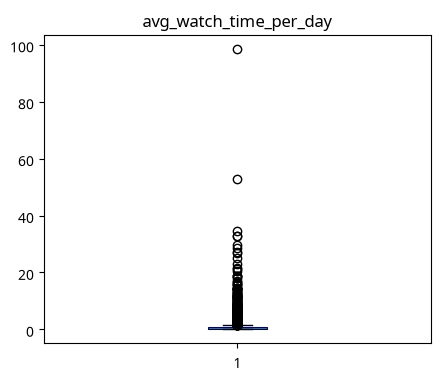

In [6]:
def plot_boxplot(data, feature):
    plt.figure(figsize=(5, 4))
    plt.boxplot(data[feature], patch_artist=True, boxprops=dict( color='navy', linewidth=0.75), medianprops=dict(color='black', linewidth=0.5))
    plt.title(feature)
    
    plt.show()

for i in numeric_predictors:
    plot_boxplot(df_prepared, i)


## 4. Удаление выбросов и создание итогового датасета

Функция по N стандартным отклонениям оставлена как альтернативный метод. Для итоговой очистки применяется правило **1,5 × IQR ко всем количественным признакам одновременно**: строка удаляется, если хотя бы один количественный признак выходит за границы. Все вычисленные границы берутся по одному датафрейму `df_prepared`, до фильтрации. Итог сохраняется в `df_clean` и используется в следующих разделах.

In [ ]:
def remove_outliers_n_std(data, feature, n=3):
    mean = data[feature].mean()
    std = data[feature].std()
    lower = mean - n * std
    upper = mean + n * std
    keep = data[feature].isna() | data[feature].between(lower, upper)
    return data.loc[keep].copy()


def remove_outliers_iqr(data, features, multiplier=1.5):
    keep_rows = pd.Series(True, index=data.index)
    report = []

    for feature in features:
        q1 = data[feature].quantile(0.25)
        q3 = data[feature].quantile(0.75)
        iqr = q3 - q1
        lower = q1 - multiplier * iqr
        upper = q3 + multiplier * iqr
        inside_bounds = data[feature].isna() | data[feature].between(lower, upper)
        outlier_count = int((~inside_bounds).sum())
        keep_rows &= inside_bounds
        
        report.append({
            "Признак": feature,
            "Нижняя граница": lower,
            "Верхняя граница": upper,
            "Выбросов по признаку": outlier_count,
        })

    cleaned_data = data.loc[keep_rows].copy()
    report = pd.DataFrame(report)
    return cleaned_data, report


rows_before_outlier_removal = len(df_prepared)
df_clean, outlier_report = remove_outliers_iqr(
    df_prepared,
    numeric_predictors,
    multiplier=1.5,
)
rows_removed = rows_before_outlier_removal - len(df_clean)

print("Строк до удаления выбросов:", rows_before_outlier_removal)
print("Строк удалено из-за выбросов:", rows_removed)
print("Строк после удаления выбросов:", len(df_clean))
display(outlier_report.round(2))

Строк до удаления выбросов: 5000
Строк удалено из-за выбросов: 666
Строк после удаления выбросов: 4334


,Признак,Нижняя граница,Верхняя граница,Выбросов по признаку
0,age,-12.00,100.00,0
1,watch_hours,-15.70,35.07,238
2,last_login_days,-30.00,90.00,0
3,monthly_fee,-4.51,31.49,0
4,number_of_profiles,-1.00,7.00,0
5,avg_watch_time_per_day,-0.80,1.64,549


Проверка пройдена: df_clean без дубликатов и пропусков.


### Результат фильтрации на приложенном датасете

Из 5 000 строк удалено **666**, в `df_clean` осталось **4 334**. По отдельным признакам отмечено 238 потенциальных выбросов в `watch_hours` и 549 — в `avg_watch_time_per_day`; количества пересекаются, поэтому сумма больше числа уникально удалённых строк. В остальных количественных признаках IQR-границы не нарушены.

Доля `churned = 1` меняется с **50,30%** в исходном наборе до **57,84%** в `df_clean`. Это заметный эффект фильтрации: необычное наблюдение не обязательно является ошибочной записью. IQR здесь — выбранное правило анализа, поэтому интерпретируйте дальнейшие результаты именно как анализ оставшейся очищенной выборки.

## 5. Универсальные функции визуализации

Следующие функции строят: гистограммы количественных признаков, столбчатые диаграммы распределений категориальных признаков и скрипичные графики зависимости между целевой переменной и предикторами.

In [8]:
def plot_histogram(data, feature, bins=30):
    plt.figure(figsize=(6, 4))
    plt.hist(data[feature].dropna(), bins=bins, edgecolor="black")
    plt.title(f"Гистограмма: {feature}")
    plt.xlabel(feature)
    plt.ylabel("Количество")
    plt.show()


def plot_category_counts(data, feature):
    counts = data[feature].value_counts(dropna=False)

    plt.figure(figsize=(7, 5))
    plt.bar(counts.index.astype(str), counts.values)
    plt.title(f"Распределение: {feature}")
    plt.xlabel(feature)
    plt.ylabel("Количество")
    plt.tight_layout()
    plt.show()


def plot_numeric_by_target(data, feature, target=target):
    classes = sorted(data[target].dropna().unique())
    values = [
        data.loc[data[target] == class_value, feature].dropna().values
        for class_value in classes
    ]

    plt.figure(figsize=(6, 4))
    plt.violinplot(values, showmeans=True, showmedians=True)
    plt.title(f"{feature} в зависимости от {target}")
    plt.xlabel(target)
    plt.ylabel(feature)
    plt.xticks(range(1, len(classes) + 1), classes)
    plt.show()


def plot_category_by_target(data, feature, target=target):
    categories = data[feature].dropna().value_counts().index
    positions = []
    values = []
    labels = []
    churn_rates = []

    for position, category in enumerate(categories, start=1):
        group = data.loc[data[feature] == category, target].dropna().values

        if len(group) == 0:
            continue

        positions.append(position)
        values.append(group)
        labels.append(str(category))
        churn_rates.append(group.mean())

    plt.figure(figsize=(7, 4))

    for position, group in zip(positions, values):
        if len(group) > 1 and np.unique(group).size > 1:
            plt.violinplot(
                [group],
                positions=[position],
                showmeans=True,
                showmedians=True
            )
        else:
            plt.scatter(position, group.mean(), color="blue")

    plt.scatter(
        positions,
        churn_rates,
        color="red",
        label="Средняя доля оттока",
        zorder=3
    )
    plt.title(f"{target} в зависимости от {feature}")
    plt.xlabel(feature)
    plt.ylabel(target)
    plt.xticks(positions, labels, rotation=35, ha="right")
    plt.legend()
    plt.tight_layout()
    plt.show()

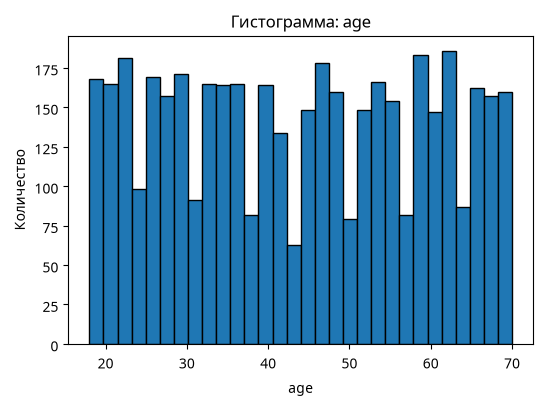

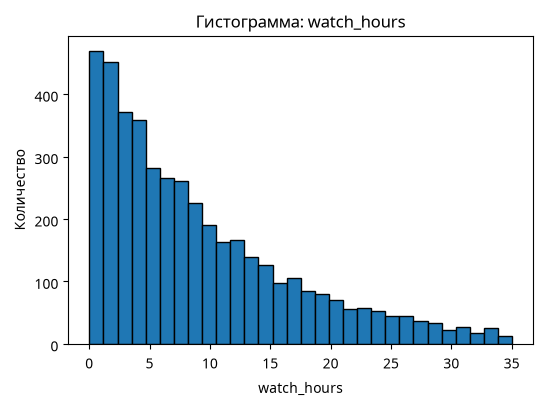

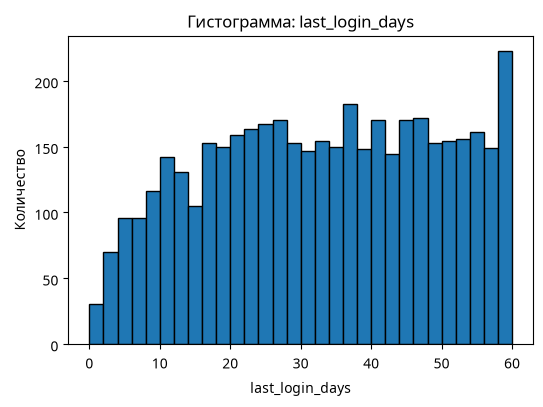

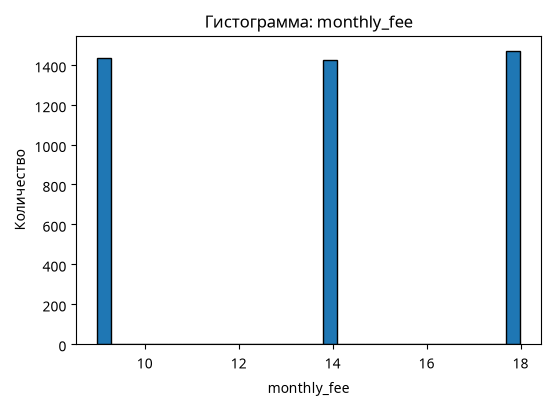

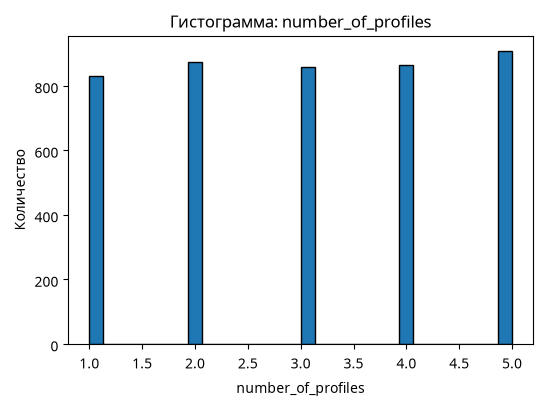

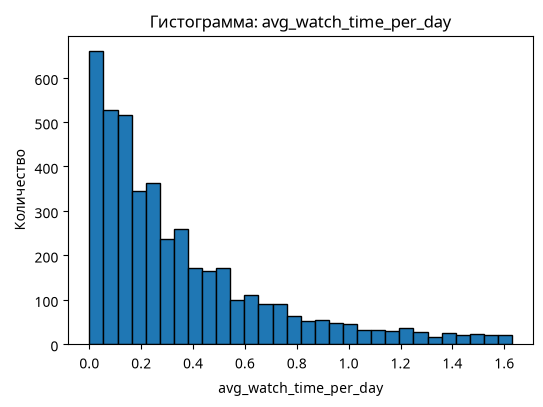

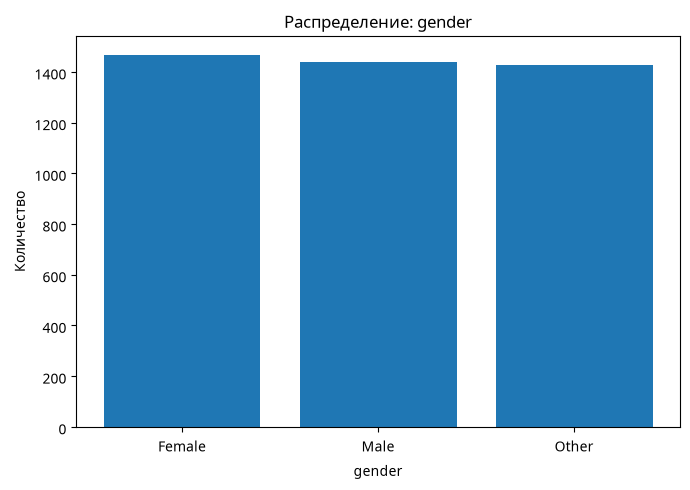

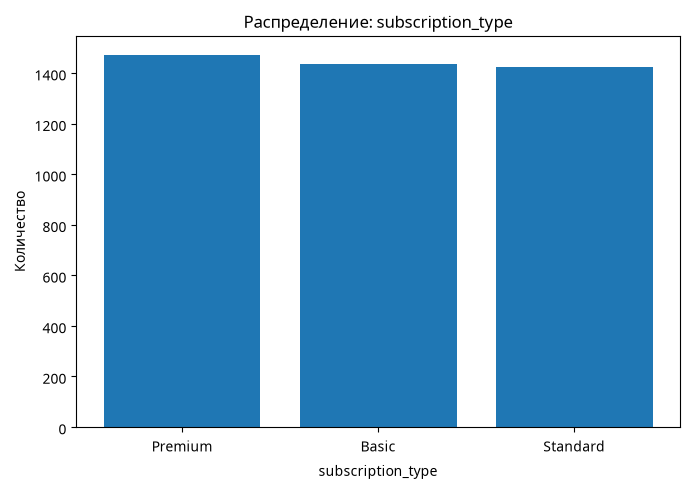

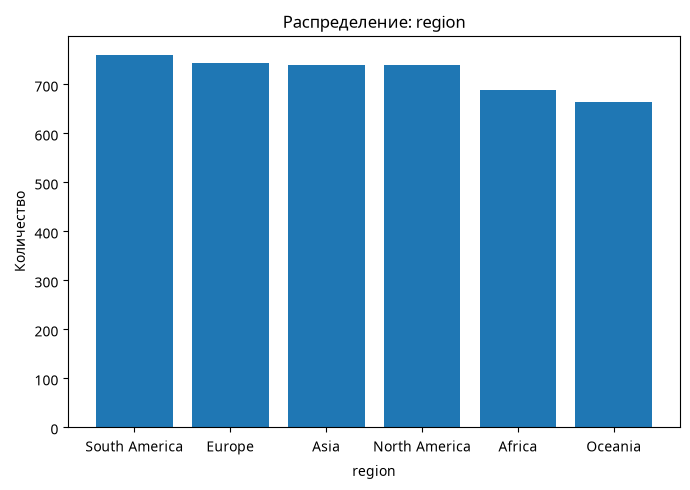

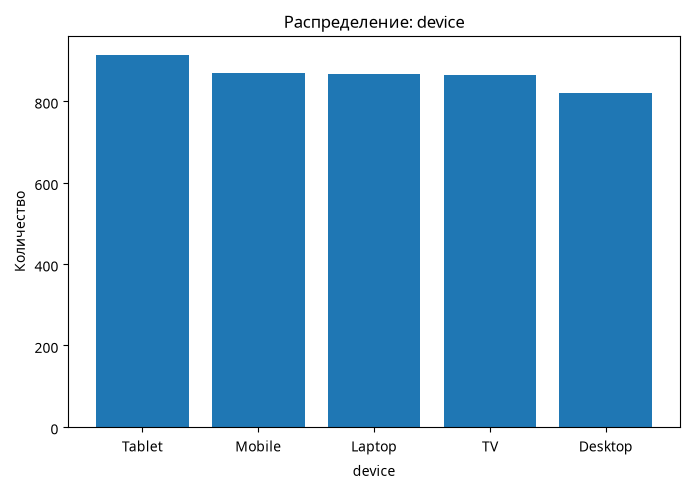

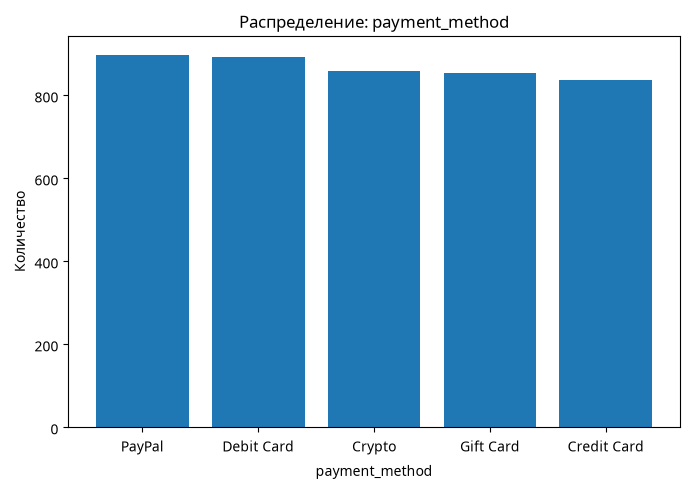

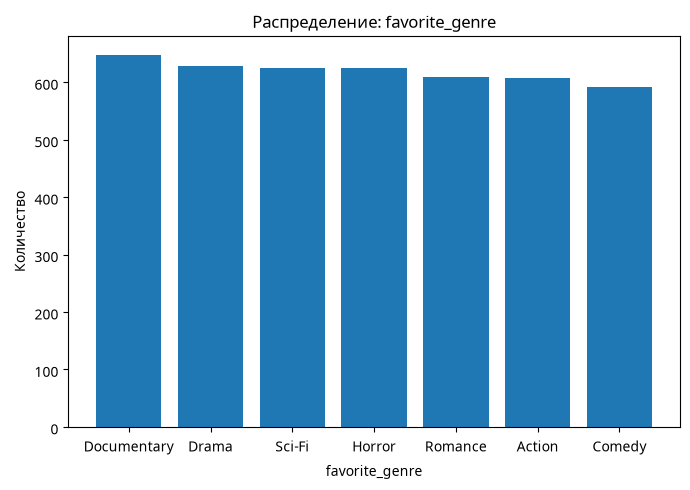

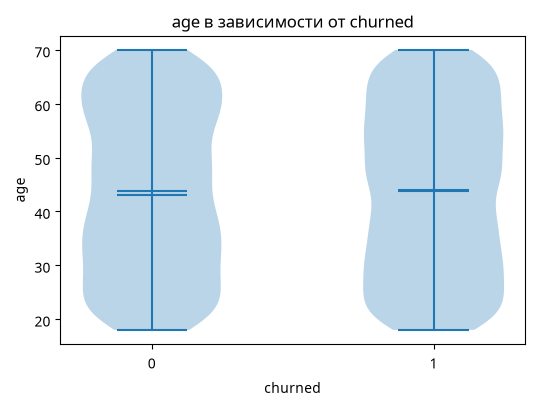

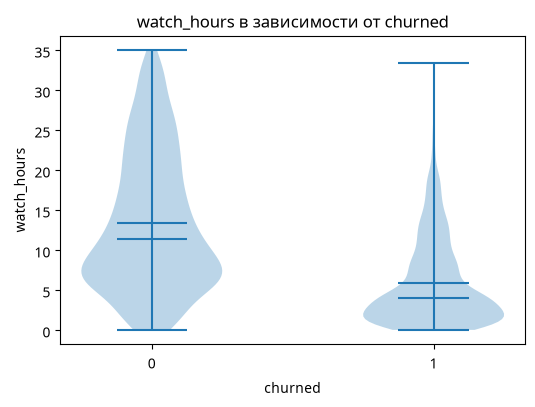

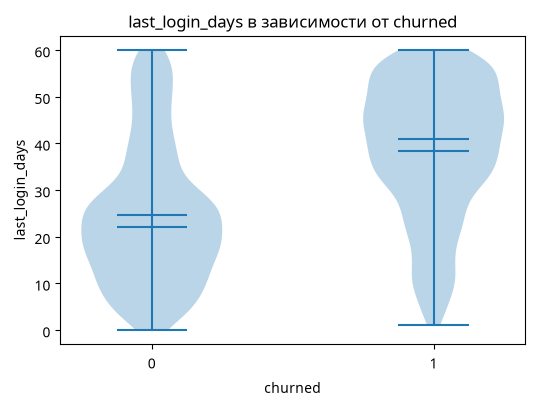

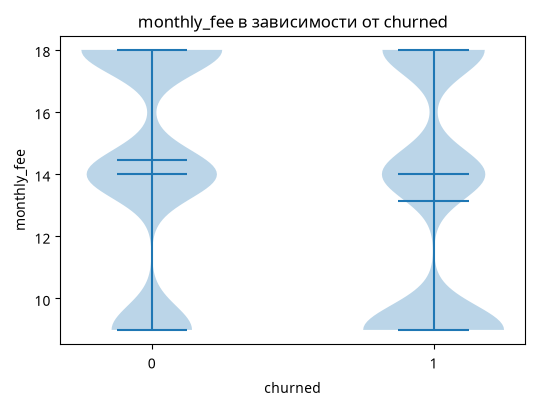

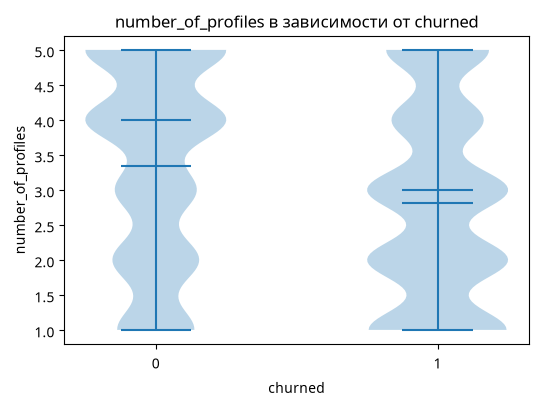

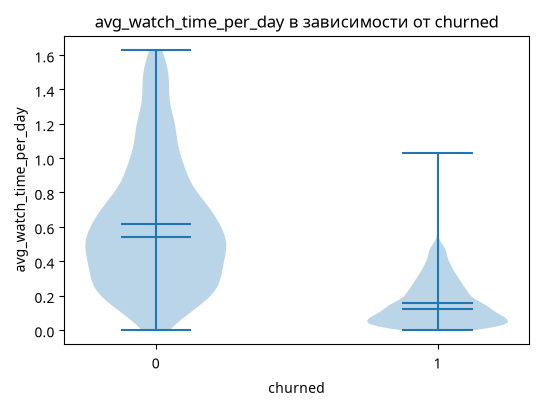

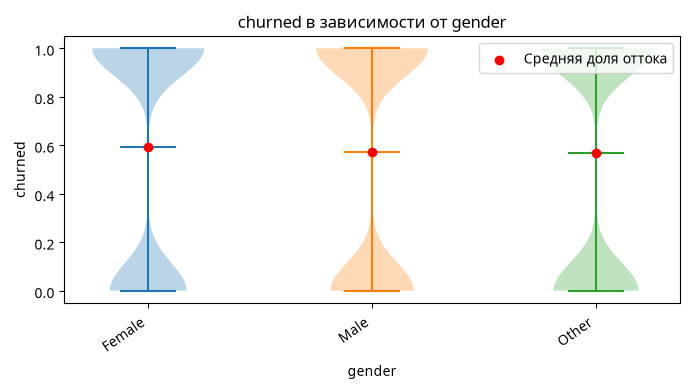

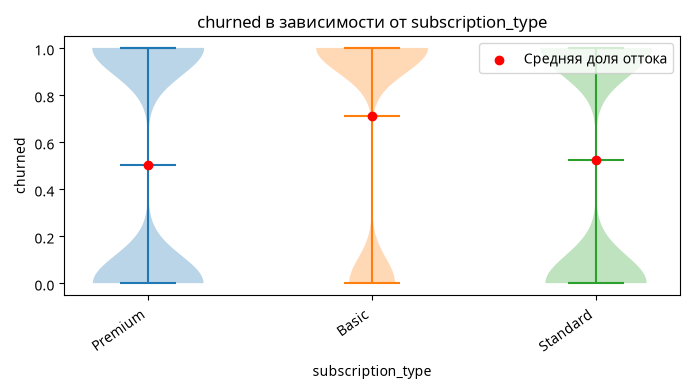

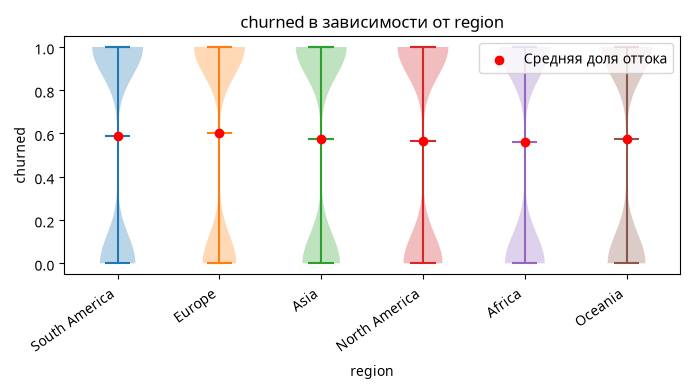

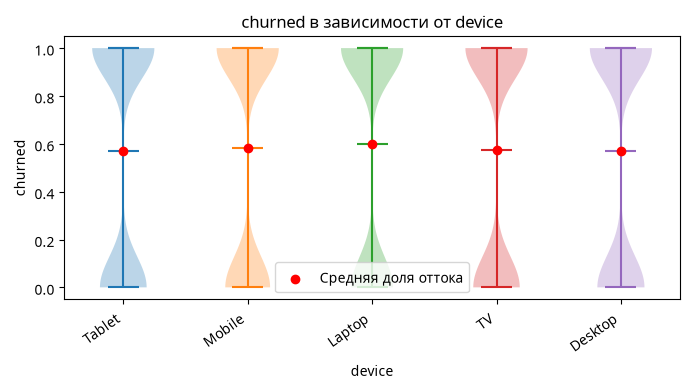

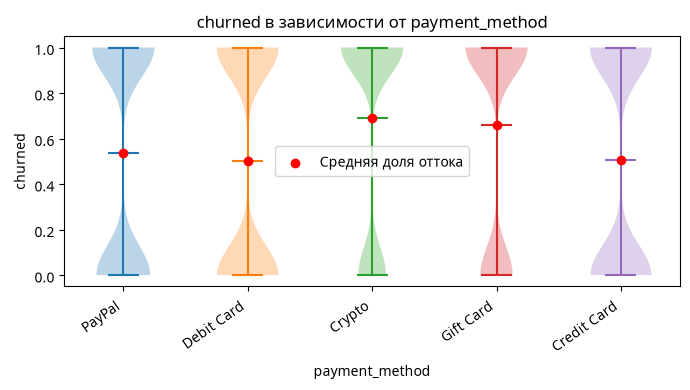

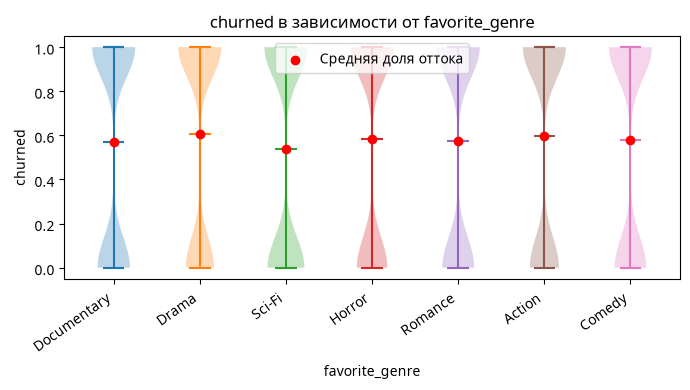

In [9]:
plot_histogram(df_clean, "age")
plot_histogram(df_clean, "watch_hours")
plot_histogram(df_clean, "last_login_days")
plot_histogram(df_clean, "monthly_fee")
plot_histogram(df_clean, "number_of_profiles")
plot_histogram(df_clean, "avg_watch_time_per_day")

plot_category_counts(df_clean, "gender")
plot_category_counts(df_clean, "subscription_type")
plot_category_counts(df_clean, "region")
plot_category_counts(df_clean, "device")
plot_category_counts(df_clean, "payment_method")
plot_category_counts(df_clean, "favorite_genre")

plot_numeric_by_target(df_clean, "age")
plot_numeric_by_target(df_clean, "watch_hours")
plot_numeric_by_target(df_clean, "last_login_days")
plot_numeric_by_target(df_clean, "monthly_fee")
plot_numeric_by_target(df_clean, "number_of_profiles")
plot_numeric_by_target(df_clean, "avg_watch_time_per_day")

plot_category_by_target(df_clean, "gender")
plot_category_by_target(df_clean, "subscription_type")
plot_category_by_target(df_clean, "region")
plot_category_by_target(df_clean, "device")
plot_category_by_target(df_clean, "payment_method")
plot_category_by_target(df_clean, "favorite_genre")

## 6. Описательные статистики целевого признака и интерпретация

In [10]:
print(df_clean[target].describe())

target_counts = df_clean[target].value_counts().sort_index()
target_percent = df_clean[target].value_counts(normalize=True).sort_index() * 100

target_summary = pd.DataFrame({
    "Количество": target_counts,
    "Доля, %": target_percent.round(2),
})

display(target_summary)


count    4334.000000
mean        0.578449
std         0.493864
min         0.000000
25%         0.000000
50%         1.000000
75%         1.000000
max         1.000000
Name: churned, dtype: float64


,Количество,"Доля, %"
churned,,
0,1827,42.16
1,2507,57.84


### Интерпретация описательных статистик

- В очищенной выборке **4 334 клиента**.
- Целевой признак `churned` распределён неравномерно: у **2 507 клиентов (57,84%)** зафиксирован отток, у **1 827 (42,16%)** — нет. Классы не равны по размеру, но представлены достаточно широко.
- **Возраст (`age`)**: среднее — 43,78 года, медиана — 44, диапазон — 18–70. Близость среднего и медианы не указывает на выраженную асимметрию.
- **Время просмотра (`watch_hours`)**: среднее — 9,07 часа, медиана — 6,86, стандартное отклонение — 7,84. Среднее выше медианы, что указывает на правостороннюю асимметрию даже после удаления выбросов; максимальное оставшееся значение — 35,03.
- **Дни с последнего входа (`last_login_days`)**: среднее — 32,61 дня, медиана — 33, диапазон — 0–60. Среднее и медиана близки.
- **Месячная плата (`monthly_fee`)**: среднее — 13,69, медиана — 13,99. Признак принимает три значения тарифа: 8,99, 13,99 и 17,99, поэтому распределение дискретное.
- **Число профилей (`number_of_profiles`)**: среднее — 3,03, медиана — 3, диапазон — от 1 до 5 профилей.
- **Среднее дневное время просмотра (`avg_watch_time_per_day`)**: среднее — 0,35, медиана — 0,24, стандартное отклонение — 0,35. Среднее выше медианы, что указывает на правый хвост распределения; после фильтрации максимум составляет 1,63.
- Эти статистики рассчитаны **после удаления строк с выбросами по правилу 1,5 × IQR**. Они описывают оставшуюся выборку, а не все исходные записи.


### Интерпретация целевого признака

Таблица выше рассчитана по итоговому очищенному `df_clean`, а не по исходному CSV. Среднее бинарного `churned` равно доле оставшихся в анализе клиентов с оттоком. Удаление строк выбросов может изменить число наблюдений и доли классов. Интерпретацию нужно проводить по обновленной таблице.

## 7. Дескриптивные таблицы предикторов и интерпретация

In [11]:

numeric_features = [
    "age",
    "watch_hours",
    "last_login_days",
    "monthly_fee",
    "number_of_profiles",
    "avg_watch_time_per_day",
]

categorical_features = [
    "gender",
    "subscription_type",
    "region",
    "device",
    "payment_method",
    "favorite_genre",
]
numeric_summary = df_clean[numeric_features].describe().T.round(2)
display(numeric_summary)


,count,mean,std,min,25%,50%,75%,max
age,4334.0,43.78,15.47,18.00,30.00,44.00,57.00,70.00
watch_hours,4334.0,9.07,7.84,0.01,2.89,6.86,13.21,35.03
last_login_days,4334.0,32.61,16.28,0.00,19.00,33.00,46.00,60.00
monthly_fee,4334.0,13.69,3.69,8.99,8.99,13.99,17.99,17.99
number_of_profiles,4334.0,3.03,1.42,1.00,2.00,3.00,4.00,5.00
avg_watch_time_per_day,4334.0,0.35,0.35,0.00,0.10,0.24,0.49,1.63


In [12]:


for feature in categorical_features:
    print("\nРаспределение признака:", feature)
    print(df_clean[feature].value_counts())


Распределение признака: gender
gender
Female    1468
Male      1438
Other     1428
Name: count, dtype: int64

Распределение признака: subscription_type
subscription_type
Premium     1472
Basic       1437
Standard    1425
Name: count, dtype: int64

Распределение признака: region
region
South America    760
Europe           743
Asia             739
North America    739
Africa           689
Oceania          664
Name: count, dtype: int64

Распределение признака: device
device
Tablet     914
Mobile     869
Laptop     867
TV         865
Desktop    819
Name: count, dtype: int64

Распределение признака: payment_method
payment_method
PayPal         897
Debit Card     892
Crypto         858
Gift Card      852
Credit Card    835
Name: count, dtype: int64

Распределение признака: favorite_genre
favorite_genre
Documentary    648
Drama          628
Sci-Fi         625
Horror         625
Romance        609
Action         608
Comedy         591
Name: count, dtype: int64


In [13]:
for feature in categorical_features:
    print("\nДоля оттока по признаку:", feature)

    churn_rate = df_clean.groupby(feature, observed=True)[target].mean() * 100
    print(churn_rate.round(2))


Доля оттока по признаку: gender
gender
Female    59.33
Male      57.30
Other     56.86
Name: churned, dtype: float64

Доля оттока по признаку: subscription_type
subscription_type
Basic       70.91
Premium     50.27
Standard    52.49
Name: churned, dtype: float64

Доля оттока по признаку: region
region
Africa           56.17
Asia             57.51
Europe           60.30
North America    56.56
Oceania          57.38
South America    58.95
Name: churned, dtype: float64

Доля оттока по признаку: device
device
Desktop    56.90
Laptop     59.86
Mobile     58.11
TV         57.23
Tablet     57.11
Name: churned, dtype: float64

Доля оттока по признаку: payment_method
payment_method
Credit Card    50.54
Crypto         69.23
Debit Card     50.34
Gift Card      65.85
PayPal         53.62
Name: churned, dtype: float64

Доля оттока по признаку: favorite_genre
favorite_genre
Action         59.70
Comedy         57.70
Documentary    57.10
Drama          60.51
Horror         58.56
Romance        57.47


### Интерпретация предикторов

Таблицы и графики в этом разделе рассчитаны по итоговому `df_clean`: дубликаты удалены, пропуски обработаны, а строки с выбросами по правилу 1,5 × IQR исключены. Сравнивайте среднее с медианой и квартилями для оценки асимметрии. После удаления выбросов средние, максимумы и доли категорий могут отличаться от статистик исходного датасета.


## 8. Перекодирование категориальных признаков

Ниже реализованы три требуемых варианта. `customer_id` не используется: это уникальный технический идентификатор, который не следует кодировать как предиктор.

1. **One-Hot Encoding** — только для бинарных категориальных предикторов.
2. **LabelEncoder** — для одного номинального признака `favorite_genre`.
3. **OrdinalEncoder** — для упорядоченного признака `subscription_type`: `Basic < Standard < Premium`.

In [14]:
def one_hot_binary(data, features):
    result = data.copy()
    binary_features = []
    for feature in features:
        if result[feature].nunique() == 2:
            binary_features.append(feature)
    result = pd.get_dummies(
        result,
        columns=binary_features,
        dtype=int
    )

    return result

df_encoded = df_clean.drop(columns=["customer_id"], errors="ignore").copy()

genre_encoder = LabelEncoder()

df_encoded["favorite_genre_label"] = genre_encoder.fit_transform(
    df_encoded["favorite_genre"]
)

print("Кодирование жанров:")
for category, number in zip(
    genre_encoder.classes_,
    genre_encoder.transform(genre_encoder.classes_)
):
    print(category, "-", number)


subscription_order = ["Basic", "Standard", "Premium"]

subscription_encoder = OrdinalEncoder(
    categories=[subscription_order]
)

df_encoded["subscription_type_ordinal"] = (
    subscription_encoder
    .fit_transform(df_encoded[["subscription_type"]])
    .astype(int)
)

print("Кодирование типов подписки:")
for number, category in enumerate(subscription_order):
    print(category, "-", number)



df_encoded = one_hot_binary(df_encoded, categorical_features)

display(df_encoded.head())

Кодирование жанров:
Action - 0
Comedy - 1
Documentary - 2
Drama - 3
Horror - 4
Romance - 5
Sci-Fi - 6
Кодирование типов подписки:
Basic - 0
Standard - 1
Premium - 2


,age,gender,subscription_type,watch_hours,last_login_days,region,device,monthly_fee,churned,payment_method,number_of_profiles,avg_watch_time_per_day,favorite_genre,favorite_genre_label,subscription_type_ordinal
0,51,Other,Basic,14.73,29,Africa,TV,8.99,1,Gift Card,1,0.49,Action,0,0
1,47,Other,Standard,0.70,19,Europe,Mobile,13.99,1,Gift Card,5,0.03,Sci-Fi,6,1
2,27,Female,Standard,16.32,10,Asia,TV,13.99,0,Crypto,2,1.48,Drama,3,1
3,53,Other,Premium,4.51,12,Oceania,TV,17.99,1,Crypto,2,0.35,Horror,4,2
4,56,Other,Standard,1.89,13,Africa,Mobile,13.99,1,Crypto,2,0.13,Action,0,1


### Итог кодирования

В текущем датасете нет бинарных категориальных **предикторов**: у всех шести категориальных переменных от 3 до 7 уровней. Поэтому функция One-Hot Encoding корректно не создаёт фиктивных колонок, но готова обработать бинарный признак при появлении такого столбца в новом файле.

`subscription_type` действительно является порядковым признаком, поэтому кодирование `Basic → 0`, `Standard → 1`, `Premium → 2` сохраняет его смысловой порядок. Для `favorite_genre` создана отдельная колонка `favorite_genre_label`; исходная колонка сохраняется для читаемости и дальнейшего выбора стратегии моделирования.

> Для алгоритмов, чувствительных к расстояниям и линейным коэффициентам, номинальный `favorite_genre` обычно лучше также преобразовать через One-Hot Encoding, а не использовать числовые метки LabelEncoder. Здесь LabelEncoder применён именно как требуемый вариант перекодирования.

## 9. Корреляционный анализ

Корреляции рассчитываются для очищенной когорты: числовые данные берутся из `df_encoded`, который создан из `df_clean`, а индикаторы категорий — непосредственно из `df_clean`.

In [15]:
correlation_data = df_encoded[numeric_features + [target]].copy()

feature_info = {}

for feature in numeric_features:
    feature_info[feature] = {
        "признак": feature,
        "категория": "—",
    }

for feature in categorical_features:
    categories = df_clean[feature].fillna("Пропуск").astype(str)

    for category in categories.unique():
        column_name = f"{feature} = {category}"

        correlation_data[column_name] = (
            categories == category
        ).astype(int)

        feature_info[column_name] = {
            "признак": feature,
            "категория": category,
        }

correlation_data = correlation_data.loc[
    :, correlation_data.nunique(dropna=True) > 1
]

print("Размер таблицы для анализа корреляций:", correlation_data.shape)


pair_feature = "watch_hours"
#pair_feature = input('Введите название признака для корреляции: ')

pearson_value = correlation_data[target].corr(
    correlation_data[pair_feature],
    method="pearson"
)

spearman_value = correlation_data[target].corr(
    correlation_data[pair_feature],
    method="spearman"
)

print(f"Предиктор: {pair_feature}")
print(f"Корреляция Пирсона: {pearson_value}")
print(f"Корреляция Спирмена: {spearman_value}")

pearson_matrix = correlation_data.corr(method="pearson")

spearman_matrix = correlation_data.corr(method="spearman")

print("Матрица корреляций Пирсона:")
display(pearson_matrix.round(2))

print("Матрица корреляций Спирмена:")
display(spearman_matrix.round(2))




Размер таблицы для анализа корреляций: (4334, 36)
Предиктор: watch_hours
Корреляция Пирсона: -0.473858603373227
Корреляция Спирмена: -0.473001137736742
Матрица корреляций Пирсона:


,age,watch_hours,last_login_days,monthly_fee,number_of_profiles,avg_watch_time_per_day,churned,gender = Other,gender = Female,gender = Male,...,payment_method = Debit Card,payment_method = PayPal,payment_method = Credit Card,favorite_genre = Action,favorite_genre = Sci-Fi,favorite_genre = Drama,favorite_genre = Horror,favorite_genre = Romance,favorite_genre = Comedy,favorite_genre = Documentary
age,1.00,0.02,0.02,-0.02,0.01,0.01,0.00,0.01,-0.00,-0.01,...,-0.02,0.00,-0.01,-0.00,-0.01,-0.01,0.01,0.01,0.01,0.00
watch_hours,0.02,1.00,0.14,0.01,-0.01,0.62,-0.47,0.01,-0.02,0.01,...,0.00,-0.01,0.02,-0.03,0.00,0.01,-0.02,0.03,0.01,0.00
last_login_days,0.02,0.14,1.00,-0.01,-0.00,-0.48,0.42,-0.01,-0.03,0.03,...,-0.02,-0.00,-0.02,-0.01,-0.04,0.01,-0.00,0.03,0.00,0.02
monthly_fee,-0.02,0.01,-0.01,1.00,0.02,0.01,-0.18,0.00,-0.02,0.02,...,0.01,-0.03,-0.01,-0.03,0.01,0.01,0.03,-0.02,-0.03,0.02
number_of_profiles,0.01,-0.01,-0.00,0.02,1.00,-0.02,-0.19,0.01,0.01,-0.02,...,0.01,0.01,-0.02,-0.00,0.00,-0.01,0.01,-0.00,-0.02,0.03
avg_watch_time_per_day,0.01,0.62,-0.48,0.01,-0.02,1.00,-0.65,0.01,0.01,-0.02,...,0.01,-0.02,0.03,-0.01,0.03,-0.02,-0.02,0.00,0.00,0.02
churned,0.00,-0.47,0.42,-0.18,-0.19,-0.65,1.00,-0.01,0.02,-0.01,...,-0.08,-0.04,-0.07,0.02,-0.03,0.02,0.01,-0.00,-0.00,-0.01
gender = Other,0.01,0.01,-0.01,0.00,0.01,0.01,-0.01,1.00,-0.50,-0.49,...,-0.01,-0.04,0.02,-0.01,-0.03,-0.01,0.00,0.01,0.02,0.02
gender = Female,-0.00,-0.02,-0.03,-0.02,0.01,0.01,0.02,-0.50,1.00,-0.50,...,-0.00,0.01,-0.04,0.00,0.04,-0.02,-0.01,0.01,0.01,-0.02
gender = Male,-0.01,0.01,0.03,0.02,-0.02,-0.02,-0.01,-0.49,-0.50,1.00,...,0.01,0.02,0.02,0.01,-0.01,0.03,0.01,-0.02,-0.03,-0.00


Матрица корреляций Спирмена:


,age,watch_hours,last_login_days,monthly_fee,number_of_profiles,avg_watch_time_per_day,churned,gender = Other,gender = Female,gender = Male,...,payment_method = Debit Card,payment_method = PayPal,payment_method = Credit Card,favorite_genre = Action,favorite_genre = Sci-Fi,favorite_genre = Drama,favorite_genre = Horror,favorite_genre = Romance,favorite_genre = Comedy,favorite_genre = Documentary
age,1.00,0.01,0.02,-0.02,0.01,0.01,0.00,0.01,-0.00,-0.01,...,-0.02,0.00,-0.01,-0.00,-0.01,-0.01,0.01,0.01,0.01,0.00
watch_hours,0.01,1.00,0.12,0.01,-0.02,0.80,-0.47,0.01,-0.03,0.02,...,-0.00,-0.01,0.02,-0.04,-0.01,0.01,-0.01,0.04,0.01,-0.00
last_login_days,0.02,0.12,1.00,-0.01,-0.01,-0.42,0.42,-0.01,-0.02,0.03,...,-0.02,-0.00,-0.02,-0.01,-0.04,0.01,-0.01,0.03,0.00,0.02
monthly_fee,-0.02,0.01,-0.01,1.00,0.02,0.01,-0.17,0.01,-0.02,0.02,...,0.01,-0.03,-0.01,-0.03,0.01,0.01,0.03,-0.02,-0.03,0.01
number_of_profiles,0.01,-0.02,-0.01,0.02,1.00,-0.02,-0.19,0.01,0.01,-0.02,...,0.01,0.01,-0.02,-0.00,0.00,-0.01,0.01,-0.00,-0.02,0.03
avg_watch_time_per_day,0.01,0.80,-0.42,0.01,-0.02,1.00,-0.68,0.01,-0.00,-0.01,...,0.00,-0.01,0.03,-0.02,0.02,-0.01,-0.01,0.01,0.01,-0.00
churned,0.00,-0.47,0.42,-0.17,-0.19,-0.68,1.00,-0.01,0.02,-0.01,...,-0.08,-0.04,-0.07,0.02,-0.03,0.02,0.01,-0.00,-0.00,-0.01
gender = Other,0.01,0.01,-0.01,0.01,0.01,0.01,-0.01,1.00,-0.50,-0.49,...,-0.01,-0.04,0.02,-0.01,-0.03,-0.01,0.00,0.01,0.02,0.02
gender = Female,-0.00,-0.03,-0.02,-0.02,0.01,-0.00,0.02,-0.50,1.00,-0.50,...,-0.00,0.01,-0.04,0.00,0.04,-0.02,-0.01,0.01,0.01,-0.02
gender = Male,-0.01,0.02,0.03,0.02,-0.02,-0.01,-0.01,-0.49,-0.50,1.00,...,0.01,0.02,0.02,0.01,-0.01,0.03,0.01,-0.02,-0.03,-0.00


In [16]:
target_correlations = pd.DataFrame({
    "Пирсон": pearson_matrix[target],
    "Спирмен": spearman_matrix[target],
})

target_correlations = target_correlations.drop(index=target)
target_correlations = target_correlations.sort_values(
    "Пирсон",
    key=lambda values: values.abs(),
    ascending=False,
)

display(target_correlations.round(3))

,Пирсон,Спирмен
avg_watch_time_per_day,-0.652,-0.683
watch_hours,-0.474,-0.473
last_login_days,0.416,0.418
number_of_profiles,-0.188,-0.188
subscription_type = Basic,0.186,0.186
monthly_fee,-0.175,-0.170
payment_method = Crypto,0.115,0.115
subscription_type = Premium,-0.110,-0.110
payment_method = Gift Card,0.080,0.080
payment_method = Debit Card,-0.077,-0.077


In [17]:
top_rows = []

for column in target_correlations.index:
    info = feature_info[column]

    top_rows.append({
        "Признак": info["признак"],
        "Категория": info["категория"],
        "Пирсон": target_correlations.loc[column, "Пирсон"],
        "Спирмен": target_correlations.loc[column, "Спирмен"],
        "Абсолютная корреляция Пирсона": abs(
            target_correlations.loc[column, "Пирсон"]
        ),
    })

# Для каждого исходного признака оставляем категорию с самой сильной корреляцией.
top_features = (
    pd.DataFrame(top_rows)
    .sort_values("Абсолютная корреляция Пирсона", ascending=False)
    .drop_duplicates(subset="Признак")
    .head(5)
    .drop(columns="Абсолютная корреляция Пирсона")
    .reset_index(drop=True)
)

display(top_features.round(3))

,Признак,Категория,Пирсон,Спирмен
0,avg_watch_time_per_day,—,-0.652,-0.683
1,watch_hours,—,-0.474,-0.473
2,last_login_days,—,0.416,0.418
3,number_of_profiles,—,-0.188,-0.188
4,subscription_type,Basic,0.186,0.186


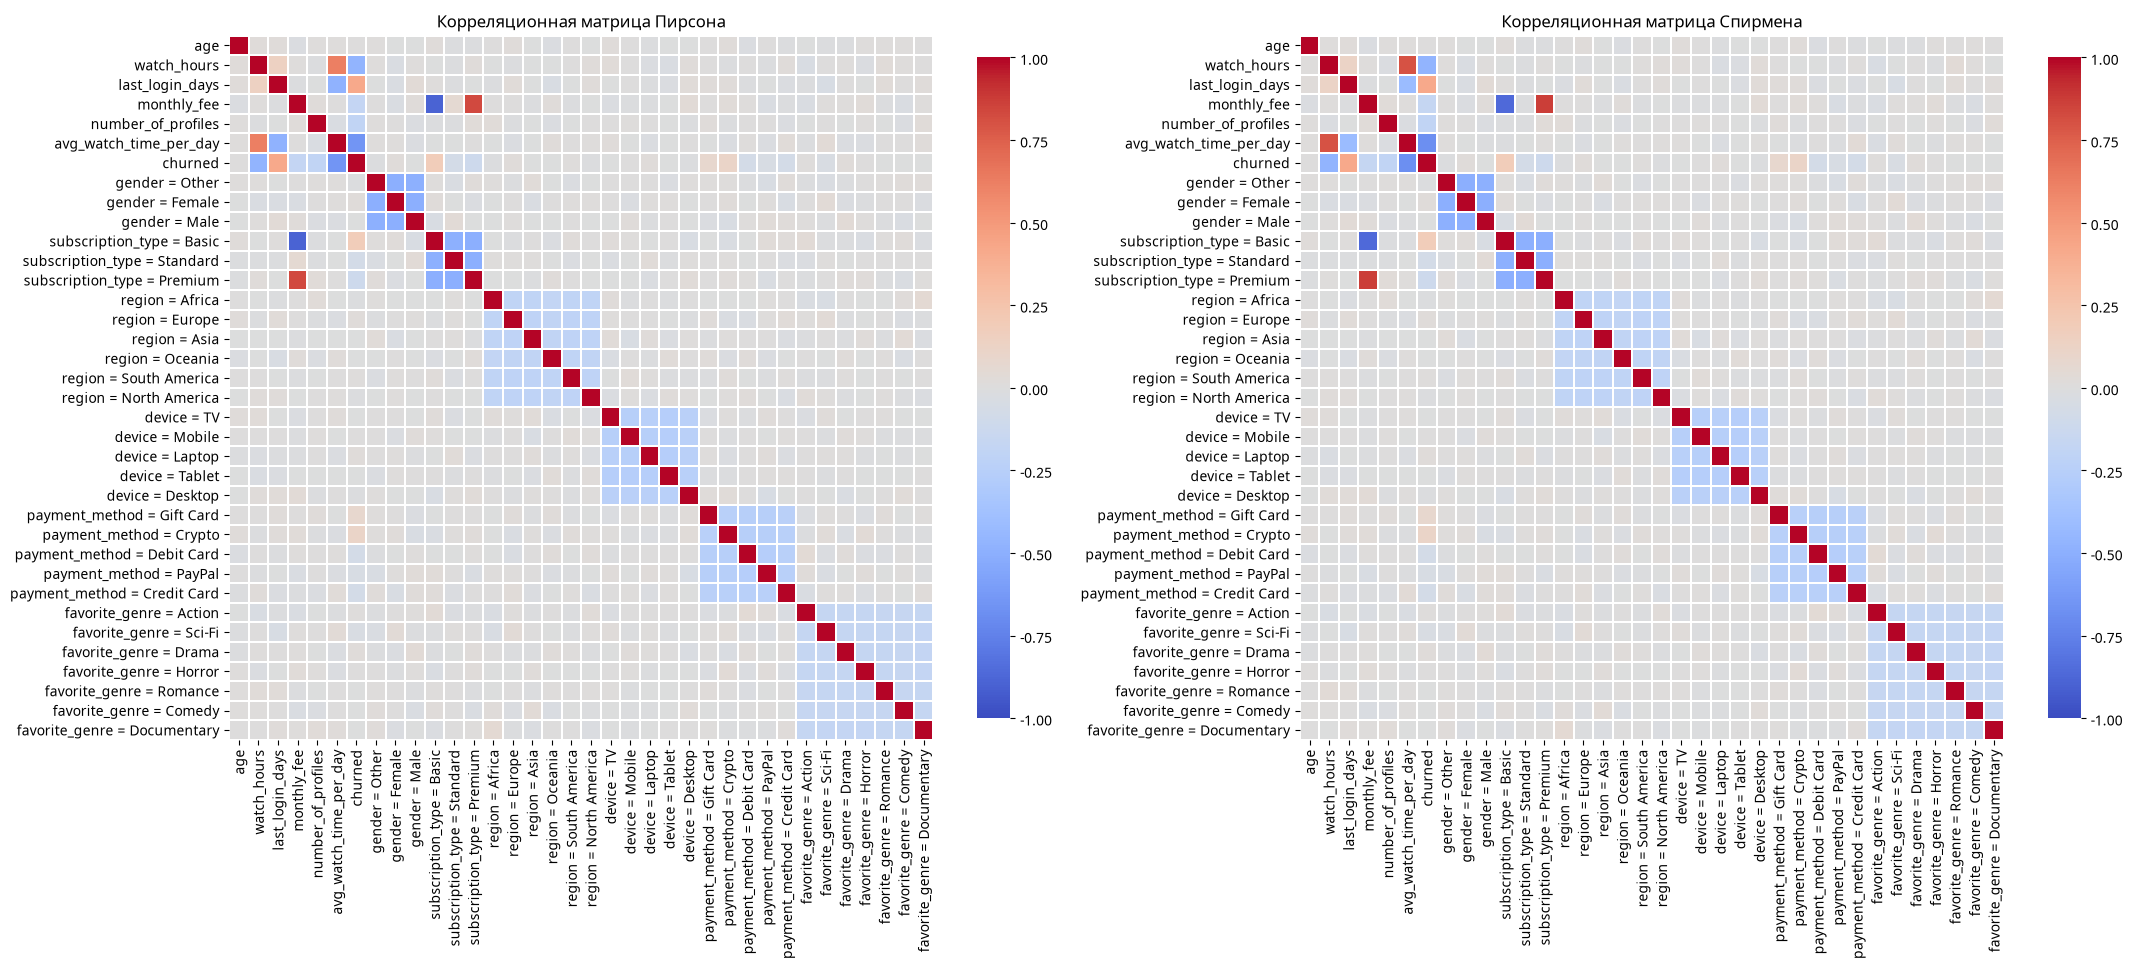

In [18]:
show_values = len(pearson_matrix.columns) <= 18

fig, axes = plt.subplots(1, 2, figsize=(22, 10))

sns.heatmap(
    pearson_matrix,
    ax=axes[0],
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    annot=show_values,
    fmt=".2f",
    square=True,
    linewidths=0.3,
    cbar_kws={"shrink": 0.8},
)
axes[0].set_title("Корреляционная матрица Пирсона")
axes[0].tick_params(axis="x", rotation=90)
axes[0].tick_params(axis="y", rotation=0)

sns.heatmap(
    spearman_matrix,
    ax=axes[1],
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    annot=show_values,
    fmt=".2f",
    square=True,
    linewidths=0.3,
    cbar_kws={"shrink": 0.8},
)
axes[1].set_title("Корреляционная матрица Спирмена")
axes[1].tick_params(axis="x", rotation=90)
axes[1].tick_params(axis="y", rotation=0)

plt.tight_layout()
plt.show()

### Интерпретация корреляционных heatmap

Тепловые карты показывают коэффициенты корреляции от −1 до +1. Значение около +1 соответствует положительной связи, около −1 — отрицательной, около 0 — слабой линейной или монотонной связи. Диагональ матрицы равна 1, поскольку каждый признак полностью коррелирует сам с собой. На цветовой шкале `coolwarm` отрицательные значения обозначены синими оттенками, положительные — красными.

Корреляция Пирсона отражает преимущественно **линейную** связь, а корреляция Спирмена — **монотонную** связь между рангами. Наиболее заметные корреляции с целевым признаком `churned`:

| Признак | Пирсон | Спирмен | Интерпретация |
|---|---:|---:|---|
| `avg_watch_time_per_day` | −0,652 | −0,683 | Сильная отрицательная связь: большее среднее время просмотра в день связано с меньшим оттоком |
| `watch_hours` | −0,474 | −0,473 | Умеренная отрицательная связь: больше часов просмотра связано с меньшим оттоком |
| `last_login_days` | +0,416 | +0,418 | Умеренная положительная связь: чем больше дней прошло с последнего входа, тем выше отток |
| `number_of_profiles` | −0,188 | −0,188 | Слабая отрицательная связь |
| `monthly_fee` | −0,175 | −0,170 | Слабая отрицательная связь |

Коэффициенты Пирсона и Спирмена для этих признаков близки, поэтому направление связи согласуется при обоих способах расчёта. Для `avg_watch_time_per_day` коэффициент Спирмена немного сильнее, что может указывать на монотонную, но не полностью линейную зависимость.

В корреляции с целевой переменной индикатор категории `subscription_type = Basic` имеет положительный коэффициент (**0,186**), тогда как `Premium` (**−0,110**) и `Standard` (**−0,076**) — отрицательные. Это согласуется с большей долей оттока среди клиентов Basic в очищенной выборке. Корреляции категорий следует трактовать как связь наличия соответствующей категории с целевой переменной, а не как причинный эффект.

Между некоторыми предикторами также видны связи. Например, `watch_hours` и `avg_watch_time_per_day` имеют сильную положительную монотонную связь по Спирмену (около **0,80**). Индикаторы уровней одной категориальной переменной могут быть отрицательно связаны между собой, поскольку один объект не может одновременно относиться к нескольким уровням одного признака. Также `monthly_fee` тесно связан с типом подписки, поскольку стоимость определяется тарифом.

Это описательные зависимости в очищенной выборке из 4 334 строк. Корреляция сама по себе не доказывает причинность и не показывает статистическую значимость: для этого нужны отдельные статистические тесты.

## 10. Модель логистической регрессии

Модель получает количественные предикторы из `df_clean`. Разделение на тренировочную и тестовую части, отбор признаков и масштабирование выполняются после очистки данных.

In [19]:
assert df_encoded.index.equals(df_clean.index), "Кодированные данные должны соответствовать df_clean."
X_all = df_clean[numeric_predictors]
y = df_clean[target]

X_train_all, X_test_all, y_train, y_test = train_test_split(
    X_all,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)

train_correlations = X_train_all.corrwith(y_train)
model_features = train_correlations.abs().sort_values(ascending=False).head(4).index.tolist()
print("Отобранные признаки:", model_features)
print("Корреляция признаков с целью на обучающей выборке:")
display(train_correlations[model_features].sort_values(key=abs, ascending=False).round(3))


X_train = X_train_all[model_features]
X_test = X_test_all[model_features]

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


model = LogisticRegression(max_iter=1000)
model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)
y_probability = model.predict_proba(X_test_scaled)[:, 1]
print("Размер тренировочной выборки:", len(X_train))
print("Размер тестовой выборки:", len(X_test))
print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))
print("Precision:", round(precision_score(y_test, y_pred), 3))
print("Recall:", round(recall_score(y_test, y_pred), 3))
print("F1:", round(f1_score(y_test, y_pred), 3))
print("ROC-AUC:", round(roc_auc_score(y_test, y_probability), 3))


print("\nМатрица ошибок [истинный класс, предсказанный класс]:")
print(confusion_matrix(y_test, y_pred))

coefficients = pd.DataFrame({
    "Признак": model_features,
    "Коэффициент": model.coef_[0],
})
coefficients["Отношение шансов"] = np.exp(coefficients["Коэффициент"])
display(coefficients.round(3))



Отобранные признаки: ['avg_watch_time_per_day', 'watch_hours', 'last_login_days', 'number_of_profiles']
Корреляция признаков с целью на обучающей выборке:


avg_watch_time_per_day   -0.650
watch_hours              -0.473
last_login_days           0.420
number_of_profiles       -0.184
dtype: float64

Размер тренировочной выборки: 3467
Размер тестовой выборки: 867
Accuracy: 0.857
Precision: 0.845
Recall: 0.922
F1: 0.882
ROC-AUC: 0.939

Матрица ошибок [истинный класс, предсказанный класс]:
[[280  85]
 [ 39 463]]


,Признак,Коэффициент,Отношение шансов
0,avg_watch_time_per_day,-2.050,0.129
1,watch_hours,-0.995,0.370
2,last_login_days,1.170,3.222
3,number_of_profiles,-0.970,0.379


### Интерпретация параметров логистической регрессии

- Модель оценивает вероятность `churned = 1` по четырём количественным признакам. Они масштабированы `StandardScaler`, поэтому коэффициенты и отношения шансов относятся к увеличению признака примерно на **одно стандартное отклонение**.
- **`avg_watch_time_per_day`**: коэффициент −2,050, отношение шансов — 0,129. При увеличении этого признака на одно стандартное отклонение шансы оттока в модели снижаются, если остальные включённые признаки неизменны.
- **`watch_hours`**: коэффициент −0,995, отношение шансов — 0,370. Более высокое время просмотра связано с меньшими модельными шансами оттока при прочих равных.
- **`last_login_days`**: коэффициент +1,170, отношение шансов — 3,222. Увеличение числа дней с последнего входа связано с ростом модельных шансов оттока.
- **`number_of_profiles`**: коэффициент −0,970, отношение шансов — 0,379. Большее число профилей связано с меньшими модельными шансами оттока при прочих равных.
- Отношение шансов — это не изменение вероятности в процентных пунктах. Коэффициенты отражают условные связи в модели, а не доказывают причинность.
- `watch_hours` и `avg_watch_time_per_day` связаны между собой, поэтому их коэффициенты следует интерпретировать с учётом остальных признаков модели; при коррелирующих предикторах отдельные оценки могут быть менее устойчивыми.

### Интерпретация метрик качества модели

- Тестовая выборка содержит **867 клиентов**. Метрики рассчитаны на одном стратифицированном разбиении 80/20.
- **Accuracy = 0,857**: модель правильно классифицировала около **85,7%** клиентов тестовой выборки.
- **Precision = 0,845**: среди клиентов, которым модель предсказала отток, около **84,5%** действительно относятся к классу оттока.
- **Recall = 0,922**: модель обнаружила около **92,2%** клиентов с фактическим оттоком; это высокий результат, если важно пропускать как можно меньше таких клиентов.
- **F1 = 0,882**: метрика показывает хороший баланс между полнотой и точностью предсказаний оттока.
- **ROC-AUC = 0,939**: модель хорошо разделяет клиентов по оценённой вероятности оттока; значение заметно выше 0,5, соответствующего случайному ранжированию.
- Матрица ошибок `[[280, 85], [39, 463]]` читается как `[истинный класс, предсказанный класс]`: **280** клиентов без оттока классифицированы верно, **85** ошибочно отнесены к оттоку, **39** клиентов с оттоком пропущены, **463** правильно распознаны как ушедшие.
- Метрики относятся к очищенной выборке после удаления выбросов. Это оценка на одном разбиении, а не гарантия качества на новых данных; для более устойчивой оценки можно дополнительно использовать кросс-валидацию.

## 11. Проверка статистических гипотез

Тесты выполняются на очищенном `df_clean`; уровень значимости `α = 0,05`. Если `p-value < α`, отвергаем нулевую гипотезу; при `p-value ≥ α` недостаточно оснований её отвергнуть. Это не означает, что нулевая гипотеза доказана.

Для строгого z-теста среднего требуется известное генеральное стандартное отклонение, которого в CSV нет; ниже показано только большевыборочное z-приближение с выборочным стандартным отклонением. Парный t-тест неприменим: в наборе нет двух согласованных измерений одного показателя для тех же клиентов. Эти ограничения пояснены отдельно.

In [20]:
alpha = 0.05
from scipy import stats

def print_test_result(test_name, statistic, p_value):
    """Печатает результат и решение при заданном уровне значимости."""
    print(test_name)
    print(f"Статистика: {statistic:.4f}")
    print(f"p-value: {p_value:.6g}")

    if p_value < alpha:
        print(f"Решение при α={alpha}: отвергаем H₀.")
    else:
        print(f"Решение при α={alpha}: недостаточно оснований отвергнуть H₀.")
        

### 11.1. Z-тест среднего: средняя месячная плата отличается от 13,99

**Словесная формулировка:** проверяем, отличается ли средняя месячная плата в очищенной выборке от 13,99 — значения тарифа Standard.

**Гипотезы:**

- `H₀: μ = 13,99`;
- `H₁: μ ≠ 13,99`.

**Предпосылки и ограничение:** наблюдения считаются независимыми, размер выборки большой, поэтому распределение выборочного среднего можно приближённо считать нормальным. Известного генерального `σ` нет; ниже используется выборочное стандартное отклонение. Это асимптотическое z-приближение, а не точный классический z-тест с известной генеральной дисперсией. При строгом требовании известной `σ` такой тест по имеющимся данным невозможен; для неизвестной `σ` формально предпочтителен одновыборочный t-тест.

In [21]:



fee = df_clean["monthly_fee"].dropna()
mu_0 = 13.99
n = len(fee)
mean_fee = fee.mean()
sigma_estimate = fee.std(ddof=1)

z_statistic = (mean_fee - mu_0) / (sigma_estimate / np.sqrt(n))
z_p_value = 2 * stats.norm.sf(abs(z_statistic))

print(f"n = {n}; среднее = {mean_fee:.3f}; выборочное s = {sigma_estimate:.3f}")
print_test_result("Большевыборочный z-тест среднего monthly_fee", z_statistic, z_p_value)

n = 4334; среднее = 13.691; выборочное s = 3.693
Большевыборочный z-тест среднего monthly_fee
Статистика: -5.3350
p-value: 9.55274e-08
Решение при α=0.05: отвергаем H₀.


### 11.2. Одновыборочный t-тест: среднее число дней с последнего входа равно 30

**Словесная формулировка:** проверяем, отличается ли среднее число дней с последнего входа у клиентов очищенной выборки от 30 дней.

**Гипотезы:**

- `H₀: μ = 30`;
- `H₁: μ ≠ 30`.

**Предпосылки:** количественная переменная и независимость наблюдений; точный t-тест предполагает нормальность генерального распределения, но при большом `n` тест среднего обычно устойчив к умеренному отклонению от нормальности. Проверку нормальности см. в тесте Шапиро–Уилка ниже.

In [22]:
login_days = df_clean["last_login_days"].dropna()
login_test = stats.ttest_1samp(login_days, popmean=30, alternative="two-sided")

print(f"n = {len(login_days)}; среднее = {login_days.mean():.3f}")
print_test_result("Одновыборочный t-тест для last_login_days", login_test.statistic, login_test.pvalue)

n = 4334; среднее = 32.611
Одновыборочный t-тест для last_login_days
Статистика: 10.5570
p-value: 9.65608e-26
Решение при α=0.05: отвергаем H₀.


### 11.3. Парный t-тест: неприменим к текущей таблице

**Задуманная гипотеза:** среднее изменение одного и того же количественного показателя у тех же клиентов между двумя моментами/условиями равно нулю (`H₀: μ_d = 0`; `H₁: μ_d ≠ 0`).

**Почему тест не проводится:** в датасете одна строка на клиента и нет двух измерений одного признака, например `watch_hours_before` и `watch_hours_after`. `watch_hours` и `avg_watch_time_per_day` нельзя объявлять парой: это разные показатели и разные единицы/периоды измерения. Проведение `ttest_rel` на них нарушило бы смысл парного теста. Потребовались бы согласованные повторные измерения каждого клиента.

### 11.4. Z-тест одной доли: доля оттока отличается от 50%

**Словесная формулировка:** проверяем, отличается ли доля клиентов с оттоком в очищенной выборке от 50%.

**Гипотезы:**

- `H₀: p = 0,50`;
- `H₁: p ≠ 0,50`.

**Предпосылки:** каждый клиент относится к одному из двух классов, наблюдения независимы, а ожидаемое число успехов и неуспехов достаточно велико. В данной выборке эти числа значительно больше 10.

In [23]:
churn = df_clean["churned"].dropna().astype(int)
p_0 = 0.50
n = len(churn)
successes = int(churn.sum())
p_hat = successes / n

z_prop = (p_hat - p_0) / np.sqrt(p_0 * (1 - p_0) / n)
p_prop = 2 * stats.norm.sf(abs(z_prop))

print(f"n = {n}; клиентов с оттоком = {successes}; доля = {p_hat:.4f}")
print_test_result("Z-тест одной доли для churned", z_prop, p_prop)

n = 4334; клиентов с оттоком = 2507; доля = 0.5784
Z-тест одной доли для churned
Статистика: 10.3291
p-value: 5.20211e-25
Решение при α=0.05: отвергаем H₀.


### 11.5. Критерий χ² Пирсона: тип подписки и отток независимы

**Словесная формулировка:** проверяем, связаны ли тип подписки и факт оттока.

**Гипотезы:**

- `H₀`: `subscription_type` и `churned` независимы;
- `H₁`: между типом подписки и оттоком есть связь.

**Предпосылки:** данные представлены частотами, категории взаимоисключающие, наблюдения независимы, ожидаемые частоты в ячейках не слишком малы. Ниже проверяются ожидаемые частоты; при малых значениях приближение χ² могло бы быть ненадёжным.

In [24]:
contingency_table = pd.crosstab(df_clean["subscription_type"], df_clean["churned"])
chi2_stat, chi2_p, chi2_dof, expected = stats.chi2_contingency(
    contingency_table,
    correction=False,
)

print("Наблюдаемые частоты:")
display(contingency_table)
print("Минимальная ожидаемая частота:", round(expected.min(), 2))
print("Степени свободы:", chi2_dof)
print_test_result("Критерий χ² независимости", chi2_stat, chi2_p)

Наблюдаемые частоты:


churned,0,1
subscription_type,,
Basic,418,1019
Premium,732,740
Standard,677,748


Минимальная ожидаемая частота: 600.71
Степени свободы: 2
Критерий χ² независимости
Статистика: 151.9890
p-value: 9.90856e-34
Решение при α=0.05: отвергаем H₀.


### 11.6. Двухвыборочный t-тест Уэлча: среднее время просмотра различается по оттоку

**Словесная формулировка:** сравниваем среднее `watch_hours` у клиентов с оттоком и без оттока.

**Гипотезы:**

- `H₀: μ₁ = μ₀`;
- `H₁: μ₁ ≠ μ₀`, где `μ₁` — среднее для `churned = 1`, `μ₀` — для `churned = 0`.

Используется вариант Уэлча (`equal_var=False`), который не требует равенства дисперсий двух групп. Группы независимы, а объёмы велики; поэтому оценка разницы средних достаточно устойчива к ненормальности. Шапиро–Уилк ниже показывает форму распределения.

In [25]:
watch_churned = df_clean.loc[df_clean["churned"] == 1, "watch_hours"].dropna()
watch_not_churned = df_clean.loc[df_clean["churned"] == 0, "watch_hours"].dropna()

welch_test = stats.ttest_ind(
    watch_churned,
    watch_not_churned,
    equal_var=False,
    alternative="two-sided",
)

print(f"Среднее watch_hours при churned=1: {watch_churned.mean():.3f}")
print(f"Среднее watch_hours при churned=0: {watch_not_churned.mean():.3f}")
print_test_result("Двухвыборочный t-тест Уэлча", welch_test.statistic, welch_test.pvalue)

Среднее watch_hours при churned=1: 5.896
Среднее watch_hours при churned=0: 13.422
Двухвыборочный t-тест Уэлча
Статистика: -33.0266
p-value: 1.276e-202
Решение при α=0.05: отвергаем H₀.


### 11.7. Критерий Манна—Уитни: распределение времени просмотра различается по оттоку

**Словесная формулировка:** проверяем, различаются ли распределения `watch_hours` у клиентов с оттоком и без оттока.

**Гипотезы:**

- `H₀`: распределения `watch_hours` в группах одинаковы;
- `H₁`: распределения различаются.

**Предпосылки:** группы независимы, показатель как минимум порядковый, наблюдения независимы. Нормальность не требуется. Критерий сравнивает ранги/распределения; трактовать его только как тест равенства медиан можно при сходной форме распределений.

In [26]:
mw_test = stats.mannwhitneyu(
    watch_churned,
    watch_not_churned,
    alternative="two-sided",
)

print(f"Медиана watch_hours при churned=1: {watch_churned.median():.3f}")
print(f"Медиана watch_hours при churned=0: {watch_not_churned.median():.3f}")
print_test_result("Критерий Манна—Уитни U", mw_test.statistic, mw_test.pvalue)

Медиана watch_hours при churned=1: 4.060
Медиана watch_hours при churned=0: 11.360
Критерий Манна—Уитни U
Статистика: 1023640.0000
p-value: 7.96158e-213
Решение при α=0.05: отвергаем H₀.


### 11.8. Шапиро—Уилк: проверка нормальности `watch_hours`

**Словесная формулировка:** проверяем, согласуются ли значения времени просмотра с нормальным распределением — в целом и отдельно в двух группах оттока.

**Гипотезы для каждой проверки:**

- `H₀`: данные группы происходят из нормального распределения;
- `H₁`: распределение отличается от нормального.

При `p < 0,05` нормальность отвергается. Большая выборка делает тест чувствительным к небольшим отклонениям; результат следует сопоставлять с гистограммой/ящиком с усами и не использовать как единственный критерий выбора метода.

In [27]:
shapiro_groups = {
    "Все клиенты": df_clean["watch_hours"].dropna(),
    "churned = 1": watch_churned,
    "churned = 0": watch_not_churned,
}

for group_name, values in shapiro_groups.items():
    shapiro_result = stats.shapiro(values)
    print(f"\n{group_name}; n={len(values)}")
    print_test_result(
        "Шапиро—Уилк для watch_hours",
        shapiro_result.statistic,
        shapiro_result.pvalue,
    )


Все клиенты; n=4334
Шапиро—Уилк для watch_hours
Статистика: 0.8892
p-value: 2.30224e-48
Решение при α=0.05: отвергаем H₀.

churned = 1; n=2507
Шапиро—Уилк для watch_hours
Статистика: 0.8704
p-value: 1.78689e-41
Решение при α=0.05: отвергаем H₀.

churned = 0; n=1827
Шапиро—Уилк для watch_hours
Статистика: 0.9462
p-value: 2.68013e-25
Решение при α=0.05: отвергаем H₀.


### 11.9. Интерпретация результатов на приложенном датасете

При `α = 0,05` получены следующие выводы для `df_clean`:

- **Z-приближение среднего `monthly_fee`:** среднее около **13,691**, что статистически отличается от 13,99 (`p ≈ 9,55 × 10⁻⁸`). По направлению выборочное среднее ниже 13,99. Это большевыборочная аппроксимация, поскольку генеральное стандартное отклонение неизвестно.
- **Одновыборочный t-тест `last_login_days`:** среднее около **32,611** дней, статистически отличается от 30 (`p ≈ 9,66 × 10⁻²⁶`) и выше заданного значения.
- **Парный t-тест:** результат не рассчитывается; отсутствуют повторные парные измерения одного показателя у тех же клиентов.
- **Z-тест доли оттока:** доля `churned = 1` составляет **57,84%** и статистически отличается от 50% (`p ≈ 5,20 × 10⁻²⁵`). Это доля после исключения выбросов, а не исходная доля в полном датасете.
- **χ² Пирсона:** есть статистически значимая связь между тарифом и оттоком (`χ² ≈ 151,989`, `p ≈ 9,91 × 10⁻³⁴`); ожидаемые частоты велики (минимум около 600,71). В очищенной выборке доля оттока составляет **70,91%** для Basic, **50,27%** для Premium и **52,49%** для Standard. Это ассоциация, не доказательство причинности.
- **t-тест Уэлча:** среднее `watch_hours` различается между группами (`p ≈ 1,28 × 10⁻²⁰²`): примерно **5,896** часа у ушедших клиентов против **13,422** у оставшихся.
- **Манн—Уитни:** распределения `watch_hours` между группами также различаются (`p ≈ 7,96 × 10⁻²¹³`); медианы — **4,06** и **11,36** часа соответственно. Это согласуется с выводом t-теста, но критерии проверяют разные характеристики.
- **Шапиро—Уилк:** нормальность `watch_hours` отвергается в общей выборке и отдельно в обеих группах (`p < 0,001`). Поэтому Welch выбран без предположения о равенстве дисперсий, с учётом больших объёмов групп; Манн—Уитни служит непараметрическим сопоставлением.

Все p-value в ячейках выведены без поправки на множественные проверки. В данном наборе они значительно ниже порога Бонферрони даже при консервативной поправке на 10 сравнений; содержательная значимость и причинность при этом не следуют автоматически из статистической значимости.

## 12. Итог проекта

Анализ выполнен на очищенном `df_clean`: удалены дубликаты, обработаны пропуски и удалены строки с IQR-выбросами. Графики после очистки, статистики, кодирование, корреляционный анализ, модель и тесты гипотез используют очищенный набор или производные от него. На приложенном CSV после очистки осталось 4 334 строки. Выводы корреляций и тестов описывают ассоциации в этой выборке и не доказывают причинность.